# Модель прогнозирования задержки в доставке

Задача: построить модель бинарной классификации, которая на основе входных данных о заказе и профиле клиента предскажет вероятность задержки доставки. 

## Содержимое проекта

- [1. Описание данных](#section1)
- [2. Постановка задачи машинного обучения](#section2)
- [3. Подготовка среды и библиотек](#section3)
- [4. Загрузка данных](#section4)
- [5. Исследовательский анализ данных (EDA)](#section5)
- [6. Предобработка данных](#section6)
- [7. Обучение базовых моделей](#section7)
- [8. Кластеризация по признакам, связанным с местоположением](#section8)
- [9. Кластеризация по признакам профилей клиентов](#section9)
- [10. Обучение моделей на новых признаках](#section10)
- [11. Тестирование лучшей модели](#section11)
- [12. Сохранение модели](#section12)
- [13. Выводы по проекту](#section13)

<h3 id="section1">1. Описание данных</h3>

Для проекта используется два источника данных:

Таблица 1. Профили клиентов:
  * `customer_id` - идентификатор клиента;
  * `customer_lat` - широта местонахождения клиента;
  * `customer_lon` - долгота местонахождения клиента;
  * `recency` - количество дней, прошедших с момента последнего заказа до точки отсчёта;
  * `total_orders` - общее количество совершённых заказов;
  * `total_sales` - суммарная выручка, которую клиент принёс компании за всё время;
  * `avg_discount` - средний размер скидки, которую получает клиент;
  * `return_rate` - доля проблемных заказов (возвратов или отмен).

Таблица 2. Заказы клиентов:
   * `order_id` - уникальный номер заказа;
   * `customer_id` - идентификатор клиента;
   * `order_date` - дата и время совершения покупки;
   * `category_name` - категория заказанного товара;
   * `item_price` - стоимость товара в заказе;
   * `shipping_mode` - выбранный режим доставки (`Standard Class`, `First Class`, `Second Class`, `Same Day`);
   * `late_delivery_risk` - результат доставки(`1` — заказ доставлен с задержкой , `0` — заказ доставлен вовремя).

<h3 id="section2">2. Постановка задачи машинного обучения</h3>

Необходимо разработать модель машинного обучения, которая на основании входных данных о заказе и профиле клиента предскажет вероятность задержки доставки.

Целевой переменной является признак доставки `late_delivery_risk`: `1` — заказ доставлен с задержкой, `0` — заказ доставлен вовремя. Таким образом, задача относится к бинарной классификации.

В рамках исследования будут использованы две модели - логистическая регрессия и градиентный бустинг CatBoost. Модели будут оценены при базовых параметрах и после добавления новых признаков с помощью кластеризации KMean++. Для проверки качества кластеризации будет построена визуализация методом t-SNE.

В качестве основной метрики для оценки качества используется ROC-AUC, так как она оценивает способность модели ранжировать заказы по степени риска. Удовлетворительным результатом для проекта является значение ROC-AUC больше 0.75.

Итогом проекта станет модель прогнозирования вероятности задержки доставки, обученная на новом наборе признаков, и достигнувшая целевой метрики ROC-AUC на уровне не менее 0.75. Разработанная модель должна помочь компании своевремнно выявлять рискованные заказы и принимать привентивные меры для снижения убытков от зажержек еще на этапе их оформления.

<h3 id="section3">3. Подготовка среды и библиотек</h3>

In [1]:
%pip -q install \
  pandas==2.2.3 \
  numpy==1.26.4 \
  scipy==1.13.1 \
  matplotlib==3.9.4 \
  scikit-learn==1.6.1 \
  phik==0.12.4 \
  seaborn==0.13.2 \
  optuna==4.8.0 \
  imbalanced-learn==0.12.4 \
  mlxtend==0.23.4 \
  numexpr==2.8.7 \
  bottleneck==1.3.6 \
  catboost==1.2.7 \
  shap==0.46.0\
  psycopg2-binary \

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score,
                             precision_score,
                             recall_score,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             silhouette_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from catboost import CatBoostClassifier
from phik import phik_matrix
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

In [3]:
# настройки отображения
pd.set_option('display.max_columns', None)

In [4]:
# фиксируем констанстанту для воспроизводимости
RANDOM_STATE = 42

<h3 id="section4">4. Загрузка данных</h3>

In [5]:
try:
    df_customer = pd.read_csv('ds_s18_customers.csv')
except:
    df_customer = pd.read_csv('https://code.s3.yandex.net/datasets/ds_s18_customers.csv')
    
try:
    df_order = pd.read_csv('ds_s18_orders.csv')
except:
    df_order = pd.read_csv('https://code.s3.yandex.net/datasets/ds_s18_orders.csv')

In [6]:
print ('Датасет df_customer:')
display(df_customer.head())
df_customer.info()

Датасет df_customer:


,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,1,25.953648,-97.507683,472.450012,1,0.060,0.0,793
1,2,38.375595,-104.726021,1618.660042,4,0.126,0.0,137
2,3,18.025375,-66.615082,3189.200037,5,0.105,0.0,230
3,4,33.670021,-112.247078,1480.709993,4,0.135,0.0,381
4,5,18.359104,-66.077911,1101.919998,3,0.140,0.0,458


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20652 entries, 0 to 20651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   20652 non-null  int64  
 1   customer_lat  20652 non-null  float64
 2   customer_lon  20652 non-null  float64
 3   total_sales   20652 non-null  float64
 4   total_orders  20652 non-null  int64  
 5   avg_discount  20652 non-null  float64
 6   return_rate   20652 non-null  float64
 7   recency       20652 non-null  int64  
dtypes: float64(5), int64(3)
memory usage: 1.3 MB


In [7]:
print ('Датасет df_order:')
display(df_order.head())
df_order.info()

Датасет df_order:


,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            180519 non-null  int64  
 1   customer_id         180519 non-null  int64  
 2   late_delivery_risk  180519 non-null  int64  
 3   shipping_mode       180519 non-null  object 
 4   category_name       180519 non-null  object 
 5   order_date          180519 non-null  object 
 6   item_price          180519 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 9.6+ MB


___Проверим наличие пропусков и дубликатов:___

In [8]:
def show_stats(df):
    stats = pd.DataFrame({
        'Количество пропусков': df.isnull().sum(),
        'Доля пропусков' : df.isnull().mean(),
        'Дубликаты': df.duplicated().sum()
    })
    stats = stats[(stats['Количество пропусков']>0) | (stats['Дубликаты']>0)]
    if stats.empty:
        return 'Пропусков и дубликатов в данных нет'
    
    return stats

In [9]:
show_stats(df_customer)

'Пропусков и дубликатов в данных нет'

In [10]:
show_stats(df_order)

'Пропусков и дубликатов в данных нет'

___Проверка целостности данных___

Посмотрим уникальность первичного ключа `customer_id` в `df_customer`:

In [11]:
print (f'Количество дубликатов customer_id в df_customer: {df_customer["customer_id"].duplicated().sum()}')

Количество дубликатов customer_id в df_customer: 0


Убедимся, что каждое значение `customer_id` из таблицы `df_order` содержится в `df_customer`:

In [12]:
missing_customers = set(df_order["customer_id"]) - set(df_customer["customer_id"])
print (f'Количество клиентов в df_order без записи в df_customer :{len(missing_customers)}')

Количество клиентов в df_order без записи в df_customer :0


Целостность между таблицами сохранена.

___Подготовим и создадим новые признаки___

In [13]:
# подготавливаем дату для создания признаков
df_order['order_date'] = pd.to_datetime(df_order['order_date'])

df_order['order_month'] = df_order['order_date'].dt.month
df_order['order_weekday'] = df_order['order_date'].dt.dayofweek
df_order['order_hour'] = df_order['order_date'].dt.hour

# удалим столбец `order_date`
df_order = df_order.drop(columns='order_date')

In [14]:
df_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            180519 non-null  int64  
 1   customer_id         180519 non-null  int64  
 2   late_delivery_risk  180519 non-null  int64  
 3   shipping_mode       180519 non-null  object 
 4   category_name       180519 non-null  object 
 5   item_price          180519 non-null  float64
 6   order_month         180519 non-null  int32  
 7   order_weekday       180519 non-null  int32  
 8   order_hour          180519 non-null  int32  
dtypes: float64(1), int32(3), int64(3), object(2)
memory usage: 10.3+ MB


Исходные данные представлены таблицей `df_customer`, содержащей 20 652 строк и 8 столбцов, и таблицей `df_order` из 180 519 записей и 7 столбцов. Содержание данных соответствует их описанию.

В ходе первичного анализа данных пропусков и полных дубликатов не  выявлено. В таблице `df_order` не обнаружено `customer_id` без записей в `df_customer`, что подтвержает целостность данных. Дополнительно из `order_date` с информацией о дате и времени заказа извлечены три новых признака - месяц `order_month`, день недели заказа `order_weekday` и время `order_hour`. Исходный признак `order_date` удален.

Категориальные признаки `shipping_mode` и `category_name` в последующем необходимо привести к типу `category` для корректной работы моделей.

<h3 id="section5">5. Исследовательский анализ данных (EDA)</h3>

#### Описание целевой переменной

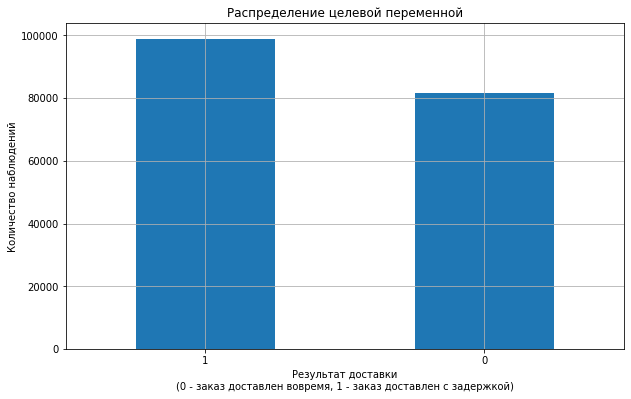

In [15]:
plt.figure(figsize = (10,6))
df_order['late_delivery_risk'].value_counts().plot(kind='bar',
                                                   xlabel='Результат доставки\n(0 - заказ доставлен вовремя, 1 - заказ доставлен с задержкой)',
                                                   ylabel='Количество наблюдений',
                                                   title='Распределение целевой переменной',
                                                   rot=0
                                                  )
plt.grid()
plt.show()

In [16]:
target_counts = pd.concat([df_order['late_delivery_risk'].value_counts(),
             round(df_order['late_delivery_risk'].value_counts(normalize=True)*100,2)],axis=1)
target_counts.columns = ['количество', 'доля, %']
display(target_counts)

,количество,"доля, %"
late_delivery_risk,,
1,98977,54.83
0,81542,45.17


Целевая перменная представлена двумя значениями: 0 - заказ доставлен вовремя, 1 - заказ доставлен с задержкой. Наблюдается умеренный дисбаланс классов - 45% данных представлены заказами, которые доставлены вовремя, и 55% заказами с задержкой.

#### Анализ категориальных признаков

___Проанализируем географические признаки `customer_lat` и `customer_lon`.___

Построем диаграмму рассеяния, чтобы увидеть зону возможных выбросов, а также окрасим в зависимости от значений признака `return_rate`.

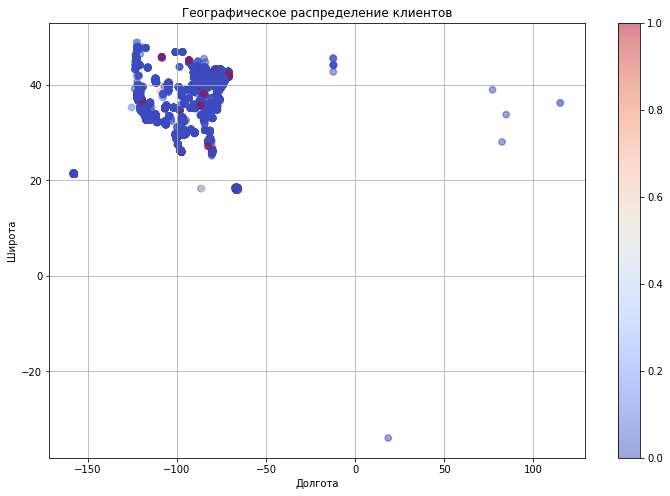

In [17]:
def geo_scatter(df_customer):
    plt.figure(figsize=(12,8))
    plt.scatter(x=df_customer['customer_lon'],
                y=df_customer['customer_lat'],
                s=40,
                c=df_customer['return_rate'],
                cmap='coolwarm', 
                linewidths=1.5,
                alpha=0.5)
    plt.xlabel('Долгота')
    plt.ylabel('Широта')
    plt.title('Географическое распределение клиентов')


    plt.colorbar()
    plt.grid()
    plt.show()
    
geo_scatter(df_customer)

Согласно диаграмме рассеяния основная часть наблюдений сосредоточена в диапазоне широты от 25 до 50 и долготы от -125 до -20, что соответствует координатам Северной Америки. Помимо основного скопления, наблюдается небольшое количество точек, значительно удаленных от основной массы наблюдений. Такие объекты можно рассматривать как потенциальные "географические выбросы".

Явной зависимости между расположением клиентов и долей проблемных заказов return_rate не наблюдается. При этом у всех удаленных наблюдений низкая доля возвратов.

Для дальнейшего анализа необходимо выполнить фильтрацию удаленных точек согласно условию их долгота выходит за пределы диапазона от -125 до -20.

Условия фильтрации:

In [18]:
anamalies = df_customer[(df_customer['customer_lon']<-125) | 
            (df_customer['customer_lon']>-20)]
print(f'Количество географических аномалий: {len(anamalies)}')

Количество географических аномалий: 156


In [19]:
df_customer = df_customer.drop(anamalies.index)

С целью сохранения целостности данных при удалении профиля клиента из `df_customer`, необходимо удалить все связанные с ним заказы из `df_order`:

In [20]:
anamalies_ids = anamalies['customer_id']
df_order = df_order[~df_order['customer_id'].isin(anamalies_ids)]

Перестроим график:

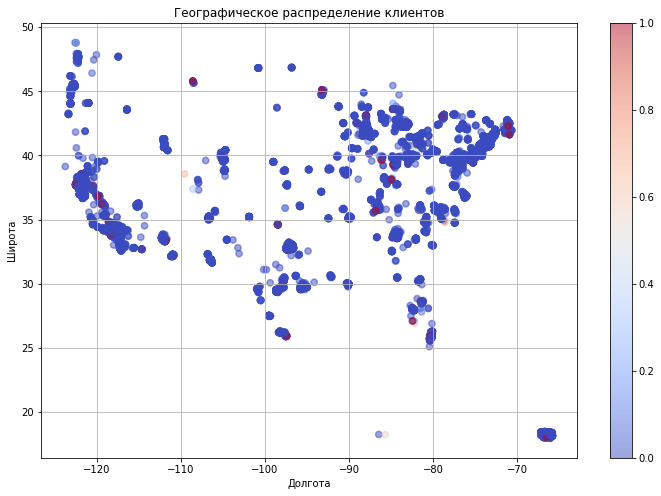

In [21]:
geo_scatter(df_customer)

Проверим точки, находящиеся ниже 20-ой широты:

In [22]:
def check_dots(condition):
    plt.figure(figsize=(8,5))
    plt.scatter(x=df_customer['customer_lon'],
                y=df_customer['customer_lat'],
                s=40, 
                linewidths=1.5,
                alpha=0.3)

    a = condition
    plt.scatter(x=a['customer_lon'],
                y=a['customer_lat'],
                s=40, 
                color='red',
                linewidths=1.5,
                alpha=0.8,
               label = 'Рассматриваемые точки')
    plt.xlabel('Долгота')
    plt.ylabel('Широта')
    plt.title('Географическое распределение клиентов')

    plt.grid()
    plt.show()
    
    display(a[['customer_lat', 'customer_lon']].head())
    print (f'Количество точек: {len(a)}')

Выделим красным точки, которые проверяем:

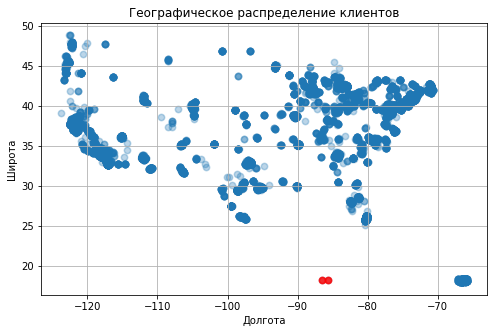

,customer_lat,customer_lon
6943,18.256500,-86.454208
6945,18.248312,-85.685257


Количество точек: 2


In [23]:
check_dots(df_customer[(df_customer['customer_lat'] < 20)&(df_customer['customer_lon'] < -80)])

Координаты соответствую открытой акватории Карибского моря, а не суши. Это может быть связано с ошибкой заполнения или сбора данных. Поскольку координаты не соотсветствуют реалистичному расположению клиентов, удалим данные наблюдения из датасета.

In [24]:
mistake_dots = df_customer[(df_customer['customer_lat'] < 20)&(df_customer['customer_lon'] < -80)]
df_customer = df_customer.drop(mistake_dots.index)
mistake_dots_ids = mistake_dots['customer_id']
df_order = df_order[~df_order['customer_id'].isin(mistake_dots_ids)]

Рассматриваем координаты далее.

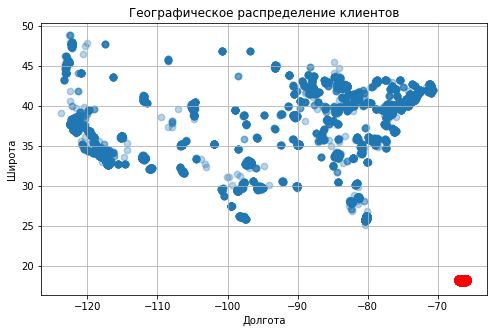

,customer_lat,customer_lon
2,18.025375,-66.615082
4,18.359104,-66.077911
6,18.359095,-66.079956
8,18.025280,-66.613068
10,18.025375,-66.615082


Количество точек: 7867


In [25]:
check_dots(df_customer[(df_customer['customer_lat'] < 20)
                &(df_customer['customer_lat'] > 0)
                &(df_customer['customer_lon'] > -80)])

Координаты принадлежат территории города Понсе (Пуэрто-Рико), данные не требуют удаления.

In [26]:
check = set(df_order["customer_id"]) -set(df_customer["customer_id"])
print (f'Количество клиентов в df_order без записи в df_customer :{len(check)}')

Количество клиентов в df_order без записи в df_customer :0


___Проанализируем режимы доставки `shipping_mode`___

In [27]:
def describe_func (df, col):
        plt.figure (figsize=(10,6))
        df[col].value_counts().head(10).plot(
                    kind='bar',
                    rot=30,
                    legend=False,
                    title=f'Распределение заказов по значениям признака {col}')
        plt.xlabel('Категории')
        plt.ylabel('Количество заказов')
        plt.grid()
        plt.show()
        
        stat = pd.concat([df[col].value_counts().head(10),
                          round(df[col].value_counts(normalize=True).head(10)*100,2)],axis=1)
        print(f'Статистические показатели по признаку {col}:')
        print(df[col].describe())
        display(stat)
        print('Уникальные значения:', df[col].unique(), '\n')
        print('Доля пропусков:', df[col].isna().mean().round(2), '\n')
        print(f'Распределение целевой переменной по категории {col}:')
        grouped = df.groupby(col, observed=False)['late_delivery_risk'].agg('mean').round(2)
        display(grouped)
       

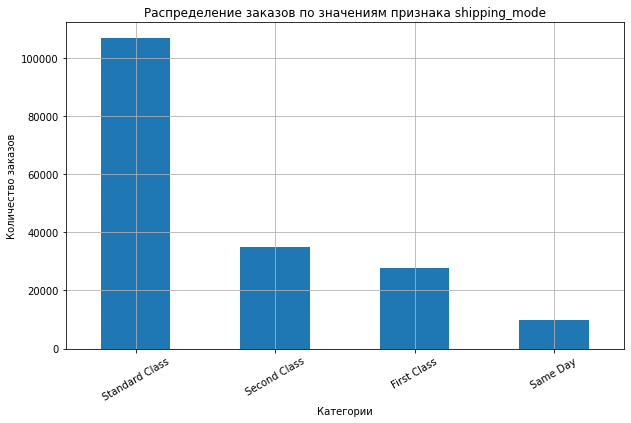

Статистические показатели по признаку shipping_mode:
count             179061
unique                 4
top       Standard Class
freq              106851
Name: shipping_mode, dtype: object


,count,proportion
shipping_mode,,
Standard Class,106851,59.67
Second Class,34942,19.51
First Class,27577,15.40
Same Day,9691,5.41


Уникальные значения: ['Standard Class' 'First Class' 'Second Class' 'Same Day'] 

Доля пропусков: 0.0 

Распределение целевой переменной по категории shipping_mode:


shipping_mode
First Class       0.95
Same Day          0.46
Second Class      0.77
Standard Class    0.38
Name: late_delivery_risk, dtype: float64

In [28]:
describe_func(df_order, 'shipping_mode')

In [29]:
df_order['shipping_mode'] = df_order['shipping_mode'].astype('category')

Признак `shipping_mode` сожержит 4 уникальных значения -  `Standard Class`, `First Class`, `Second Class`, `Same Day`. Большая часть всех заказов (60%) приходится на режим `Standard Class`, еще около 20% приходится на `Second Class`, 15% на `First Class` и оставшиеся 5% на заказы день в день `Same Day`. Доля заказов c задержкой различается в зависимости от режима доставки. Наибольшее число задержек приходится на `First Class` (0.95) и `Second Class` (0.77). Это указывает на потенциальную информативность признака. 

Для дальнейшей работы признаку `shipping_mode` присвоен тип данных category.

___Анализ категории товара `category_name`___

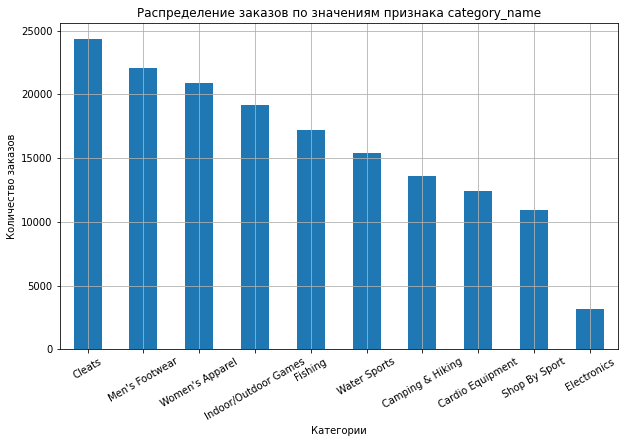

Статистические показатели по признаку category_name:
count     179061
unique        50
top       Cleats
freq       24366
Name: category_name, dtype: object


,count,proportion
category_name,,
Cleats,24366,13.61
Men's Footwear,22059,12.32
Women's Apparel,20858,11.65
Indoor/Outdoor Games,19147,10.69
Fishing,17183,9.60
Water Sports,15419,8.61
Camping & Hiking,13603,7.60
Cardio Equipment,12390,6.92
Shop By Sport,10890,6.08


Уникальные значения: ['Sporting Goods' 'Cleats' 'Shop By Sport' "Women's Apparel" 'Electronics'
 'Boxing & MMA' 'Cardio Equipment' 'Trade-In' "Kids' Golf Clubs"
 'Hunting & Shooting' 'Baseball & Softball' "Men's Footwear"
 'Camping & Hiking' 'Consumer Electronics' 'Cameras ' 'Computers'
 'Basketball' 'Soccer' "Girls' Apparel" 'Accessories' "Women's Clothing"
 'Crafts' "Men's Clothing" 'Tennis & Racquet' 'Fitness Accessories'
 'As Seen on  TV!' 'Golf Balls' 'Strength Training' "Children's Clothing"
 'Lacrosse' 'Baby ' 'Fishing' 'Books ' 'DVDs' 'CDs ' 'Garden' 'Hockey'
 'Pet Supplies' 'Health and Beauty' 'Music' 'Video Games' 'Golf Gloves'
 'Golf Bags & Carts' 'Golf Shoes' 'Golf Apparel' "Women's Golf Clubs"
 "Men's Golf Clubs" 'Toys' 'Water Sports' 'Indoor/Outdoor Games'] 

Доля пропусков: 0.0 

Распределение целевой переменной по категории category_name:


category_name
Accessories             0.57
As Seen on  TV!         0.58
Baby                    0.52
Baseball & Softball     0.55
Basketball              0.55
Books                   0.56
Boxing & MMA            0.56
CDs                     0.52
Cameras                 0.58
Camping & Hiking        0.55
Cardio Equipment        0.55
Children's Clothing     0.53
Cleats                  0.55
Computers               0.50
Consumer Electronics    0.55
Crafts                  0.56
DVDs                    0.53
Electronics             0.56
Fishing                 0.55
Fitness Accessories     0.57
Garden                  0.56
Girls' Apparel          0.55
Golf Apparel            0.52
Golf Bags & Carts       0.69
Golf Balls              0.55
Golf Gloves             0.56
Golf Shoes              0.56
Health and Beauty       0.56
Hockey                  0.54
Hunting & Shooting      0.56
Indoor/Outdoor Games    0.55
Kids' Golf Clubs        0.53
Lacrosse                0.60
Men's Clothing          0.54


In [30]:
describe_func(df_order, 'category_name')

In [31]:
df_order['category_name'] = df_order['category_name'].astype('category')

Признак категории товара содержит 50 уникальных значений. Наиболее популярны категории — спортивная обувь `Cleats` (13,6%), мужская обувь `Men’s Footwear` (12,32%), женская одежда `Women’s Apparel` (11,65%) и игры `Indoor/Outdoor Games` (10,69%). Также значительную долю занимают категории `Fishing` (9,6%), `Water Sports` (8,61%), `Camping & Hiking` (7,61%), `Cardio Equipment` (6,92%) и `Shop By Sport` (6,08%). Остальные категории представлены незначительно.
Распределие доли заказов с задержкой по категория практически равномерное.

Для дальнейшей работы признаку `category_name` присвоен тип данных category.

В ходе анализа  признаков `customer_lat` и `customer_lon` явной зависимости между расположением клиентов и долей проблемных заказов не выявлено. При этом у всех географически отдаленных наблюдений низкая доля возвратов.

При этом обнаружены 158 отдельных точек, расположенных за пределами основного региона присутствия компании. В соответствии с условиями задания географическими выбросами считаются наблюдения, у которых долгота выходит за пределы диапазона от -125 до -20. Все такие наблюдения исключены из датасета, включая координаты, которые географически соответствуют реальным объектам, но находятся за пределами целевого региона или в открытой акватории. Для сохранения целостности данных вместе с профилями клиентов удалены все связанные с ними заказы из таблицы `df_orders`.

При анализе категориальных признаков наиболее информативным оказался `shipping_mode` - доля задерженных заказов существенно различается в зависимости от режима доставки. Для признака `category_name` выраженных различий не выявлено. Типы данных признаков `shipping_mode` и `category_name` приведены к типу `category`.

#### Анализ числовых признаков

In [32]:
def visual_numeric (df, column):
        if df[column].nunique() <= 15:
            plt.figure(figsize = (10,6))
            df[column].value_counts().plot(kind = 'bar',
                                       rot=45,
                                       legend=False,
                                       title = f'Распределение данных по признаку {column}')
            plt.xlabel(column)
            plt.ylabel('Количество клиентов')
            plt.grid()
            plt.show()
            print('\nСтатистические показатели:\n')
            display(df[column].describe().round(3))
            stat = pd.concat([df[column].value_counts(),
                          round(df[column].value_counts(normalize=True)*100,2)],axis=1)
            display(stat)
        else:
            fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10, 6))
            sns.histplot(data = df,
                    x = column,
                    bins = 40,
                    kde = True,
                    ax= ax1)
            ax1.set_title(f'Распределение данных столбца {column}')
            ax1.set_xlabel(column)
            ax1.set_ylabel('Количество клиентов')
            ax1.grid()

            # диаграмма размаха
            sns.boxplot(data = df,
                        x=column,
                        ax=ax2)
            ax2.set_xlabel(column)
            ax2.grid()

            plt.tight_layout()
            plt.show()
            print('\nСтатистические показатели:\n')
            display(df[column].describe().round(3))
            

___Суммарная выручка___

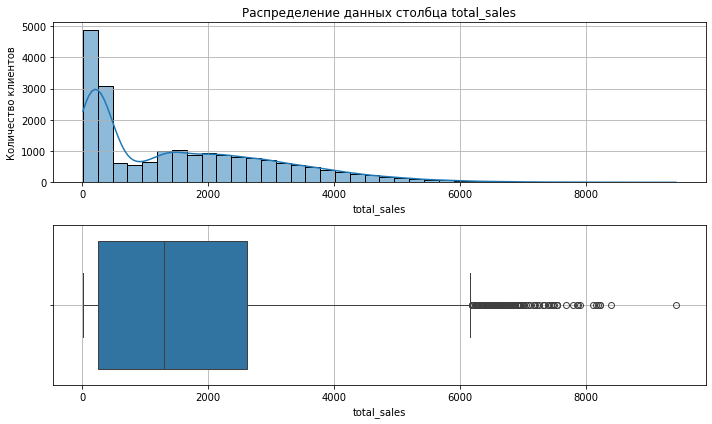


Статистические показатели:



count    20494.000
mean      1599.766
std       1508.260
min          8.470
25%        252.880
50%       1293.685
75%       2618.955
max       9436.610
Name: total_sales, dtype: float64

In [33]:
visual_numeric(df_customer, 'total_sales')

Распределение признака `total_sales` имеет выраженную правосторонюю ассиметрию: основная часть клиентов характеризируется относительно небольшими суммарными продажами. Медиана (1294) ниже среднего значения (1600), что подтверждает наличие длинного правого хвоста.

Значения отражают реальных клиентов, работа с данными не требуется.

___Количество совершенных заказов___

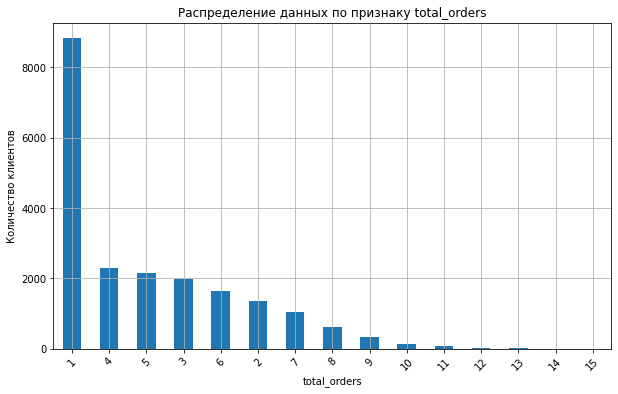


Статистические показатели:



count    20494.000
mean         3.183
std          2.430
min          1.000
25%          1.000
50%          3.000
75%          5.000
max         15.000
Name: total_orders, dtype: float64

,count,proportion
total_orders,,
1,8822,43.05
4,2307,11.26
5,2153,10.51
3,1970,9.61
6,1652,8.06
2,1353,6.60
7,1036,5.06
8,621,3.03
9,323,1.58


In [34]:
visual_numeric(df_customer, 'total_orders')

Распределение признака `total_orders` представлено диапазоном значений от 1 до 15. Большая часть клиентов совершают 1 заказ, среднее и медианное значение - 3 заказа. Аномальных значений не выявлено.

Построим диаграмму рассеяния для признаков `total_sales` и `total_orders`.

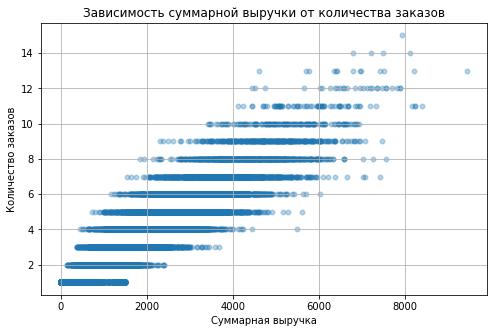

In [35]:
plt.figure(figsize=(8,5))
plt.scatter(x=df_customer['total_sales'],
                y=df_customer['total_orders'],
                s=20, 
                linewidths=1.5,
                alpha=0.3)
plt.xlabel('Суммарная выручка')
plt.ylabel('Количество заказов')
plt.title('Зависимость суммарной выручки от количества заказов')

plt.grid()
plt.show()

На диаграмме рассеяния наблюдается положительная зависимость между выручкой и количеством заказов. При этом при одинаковом количестве заказов значения выручки могут существенно различаться.

___Средний размер скидки___

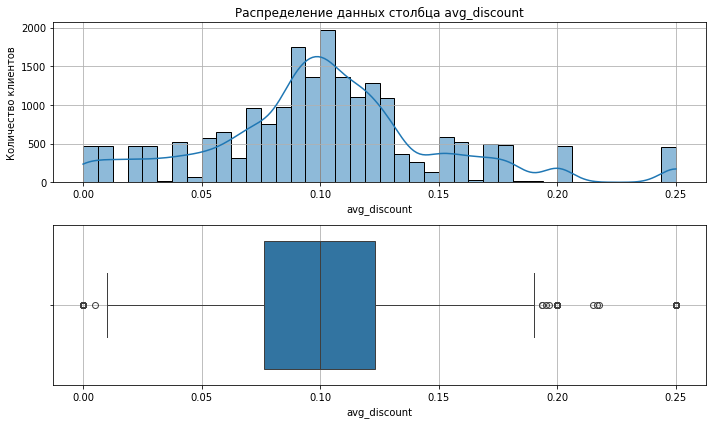


Статистические показатели:



count    20494.000
mean         0.102
std          0.048
min          0.000
25%          0.076
50%          0.100
75%          0.123
max          0.250
Name: avg_discount, dtype: float64

In [36]:
visual_numeric(df_customer, 'avg_discount')

Распределение признака `avg_discount` имеет симметричное распределение, что подтверждают схожие медианное и среднее значения на уровне 0.1. Максимальная глубина скидки для клиентов составляет 25%. Посмотрим связь скидки с количеством заказов и общей выручкой.

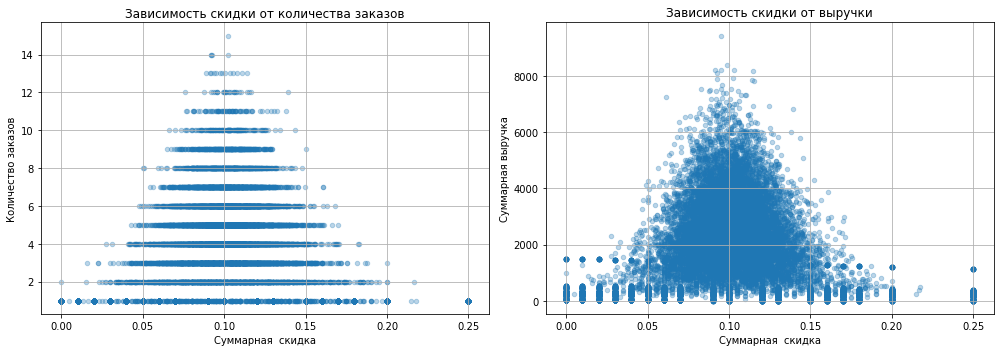

In [37]:
fig, axes = plt.subplots(1,2,figsize=(14,5))

axes[0].scatter(x=df_customer['avg_discount'],
                y=df_customer['total_orders'],
                s=20, 
                alpha=0.3)
axes[0].set_xlabel('Суммарная  скидка')
axes[0].set_ylabel('Количество заказов')
axes[0].set_title('Зависимость скидки от количества заказов')
axes[0].grid()
                         
axes[1].scatter(x=df_customer['avg_discount'],
                y=df_customer['total_sales'],
                s=20, 
                alpha=0.3)
axes[1].set_xlabel('Суммарная  скидка')
axes[1].set_ylabel('Суммарная выручка')
axes[1].set_title('Зависимость скидки от выручки')
axes[1].grid()                      
                         
plt.tight_layout()
plt.show()

Явной связи между средней скидкой и количеством заказов, как и между скидкой и суммарной выручкой, визуально не наблюдается.

___Доля проблемных заказов___

In [38]:
print('Статистические показатели:')
display(df_customer['return_rate'].describe().round(3))

Статистические показатели:


count    20494.000
mean         0.043
std          0.156
min          0.000
25%          0.000
50%          0.000
75%          0.000
max          1.000
Name: return_rate, dtype: float64

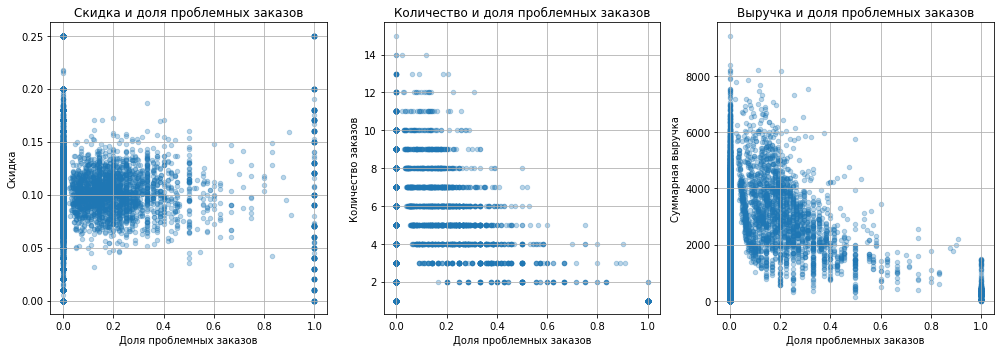

In [39]:
fig, axes = plt.subplots(1,3,figsize=(14,5))

axes[0].scatter(y=df_customer['avg_discount'],
                x=df_customer['return_rate'],
                s=20, 
                alpha=0.3)
axes[0].set_xlabel('Доля проблемных заказов')
axes[0].set_ylabel('Скидка')
axes[0].set_title('Скидка и доля проблемных заказов')
axes[0].grid()
                         
axes[1].scatter(y=df_customer['total_orders'],
                x=df_customer['return_rate'],
                s=20, 
                alpha=0.3)

axes[1].set_xlabel('Доля проблемных заказов')
axes[1].set_ylabel('Количество заказов')
axes[1].set_title('Количество и доля проблемных заказов')
axes[1].grid()   

axes[2].scatter(y=df_customer['total_sales'],
                x=df_customer['return_rate'],
                s=20, 
                alpha=0.3)

axes[2].set_xlabel('Доля проблемных заказов')
axes[2].set_ylabel('Суммарная выручка')
axes[2].set_title('Выручка и доля проблемных заказов')
axes[2].grid() 
                         
plt.tight_layout()
plt.show()

По анализу взаимосвязей можно выявить:
 - между средней скидкой и долей проблемных заказов явной засивисимости не выявлено;
 - у клиентов с небольшим количеством заказов более выскойи разброс доли проблемных заказов. По мере увеличения заказов доля проблемных заказов становится более стабильной;
 - клиенты с высокой суммарной выручкой преимущественно характеризуются более низкой долей проблемных заказов.

___Количество дней, прошедших с момента последнего заказа___

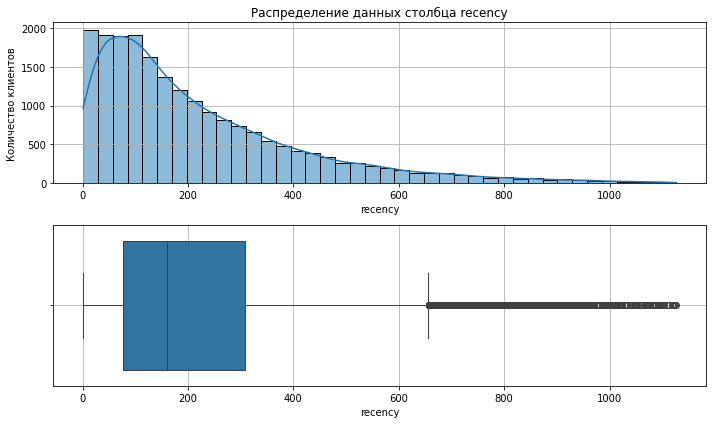


Статистические показатели:



count    20494.000
mean       221.059
std        199.331
min          1.000
25%         76.000
50%        160.000
75%        308.000
max       1126.000
Name: recency, dtype: float64

In [40]:
visual_numeric(df_customer, 'recency')

Признак recency имеет выраженную правосторонюю ассиметрию: основная часть клиентов совершают заказ в рамках одного года (308 дней). Медианное значение составляет 160 дней.

Теперь перейдем к числовым признаками таблицы `df_order`.

___Стоимость товара в заказе___

In [41]:
def visual_numeric_2(df, column):
        if df[column].nunique() <= 24:
            plt.figure(figsize = (10,6))
            df[column].value_counts().plot(kind = 'bar',
                                       rot=45,
                                       legend=False,
                                       title = f'Распределение данных по признаку {column}')
            plt.xlabel(column)
            plt.ylabel('Количество заказов')
            plt.grid()
            plt.show()
            print('\nСтатистические показатели:\n')
            display(df[column].describe().round(3))
            stat = pd.concat([df[column].value_counts(),
                          round(df[column].value_counts(normalize=True)*100,2)],axis=1)
            display(stat.head(15))
            print(f'Распределение целевой переменной по категории {col}:')
            grouped = df.groupby(column, observed=False)['late_delivery_risk'].agg('mean').round(2)
            print(grouped)
        else:
            fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10, 6))
            sns.histplot(data = df,
                    x = column,
                    bins = 40,
                    kde = True,
                    ax= ax1)
            ax1.set_title(f'Распределение данных столбца {column}')
            ax1.set_xlabel(column)
            ax1.set_ylabel('Количество заказов')
            ax1.grid()

            # диаграмма размаха
            sns.boxplot(data = df,
                        x=column,
                        ax=ax2)
            ax2.set_xlabel(column)
            ax2.grid()

            plt.tight_layout()
            plt.show()
            print('\nСтатистические показатели:\n')
            display(df[column].describe().round(3))
       

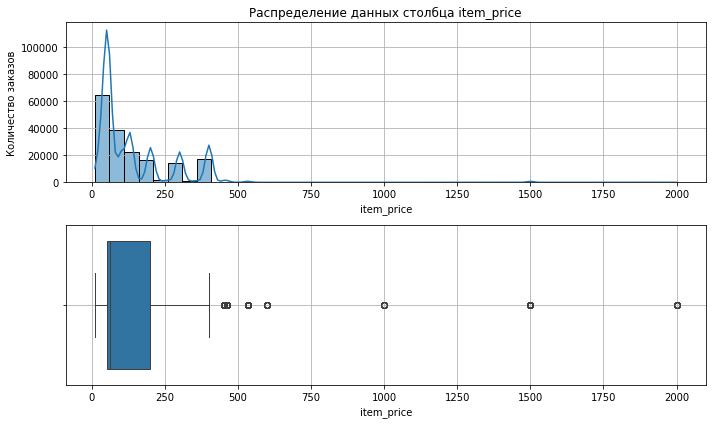


Статистические показатели:



count    179061.000
mean        141.220
std         139.777
min           9.990
25%          50.000
50%          59.990
75%         199.990
max        1999.990
Name: item_price, dtype: float64

In [42]:
visual_numeric_2(df_order, 'item_price')

Распределение признака `item_price` имеет выраженную правостороннюю асимметрию. Основная масса товаров сосредоточена в диапазоне относительно невысоких цен: медианная стоимость составляет 59,99, при этом 75% товаров имеют цену не выше 199,99. Среднее значение (141,23) существенно превышает медиану, что обусловлено наличием товаров с высокой стоимостью. 

___День, неделя и час заказа___

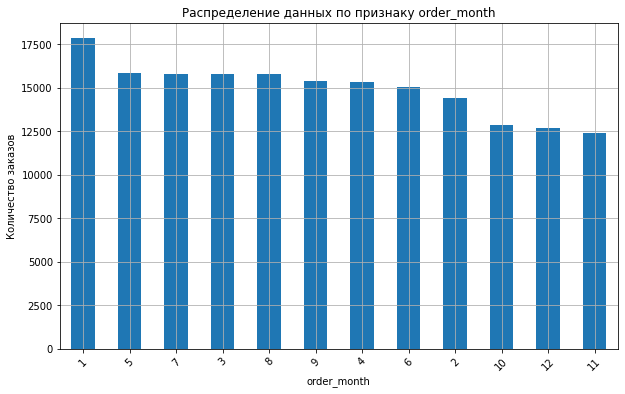


Статистические показатели:



count    179061.000
mean          6.234
std           3.403
min           1.000
25%           3.000
50%           6.000
75%           9.000
max          12.000
Name: order_month, dtype: float64

,count,proportion
order_month,,
1,17835,9.96
5,15856,8.86
7,15781,8.81
3,15780,8.81
8,15759,8.80
9,15385,8.59
4,15328,8.56
6,15027,8.39
2,14426,8.06


Распределение целевой переменной по категории order_month:
order_month
1     0.55
2     0.55
3     0.55
4     0.54
5     0.55
6     0.55
7     0.54
8     0.56
9     0.55
10    0.55
11    0.55
12    0.55
Name: late_delivery_risk, dtype: float64


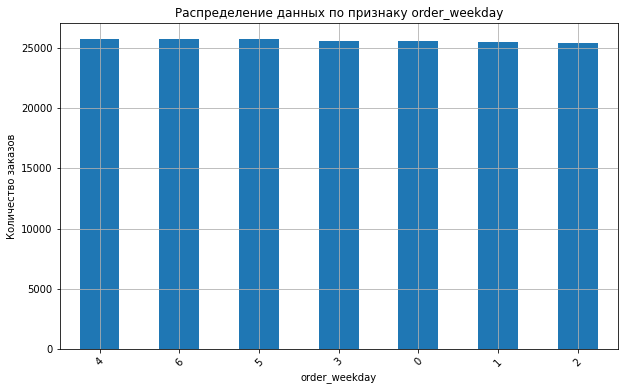


Статистические показатели:



count    179061.000
mean          3.007
std           2.001
min           0.000
25%           1.000
50%           3.000
75%           5.000
max           6.000
Name: order_weekday, dtype: float64

,count,proportion
order_weekday,,
4,25734,14.37
6,25711,14.36
5,25682,14.34
3,25557,14.27
0,25553,14.27
1,25464,14.22
2,25360,14.16


Распределение целевой переменной по категории order_weekday:
order_weekday
0    0.55
1    0.54
2    0.55
3    0.55
4    0.55
5    0.54
6    0.55
Name: late_delivery_risk, dtype: float64


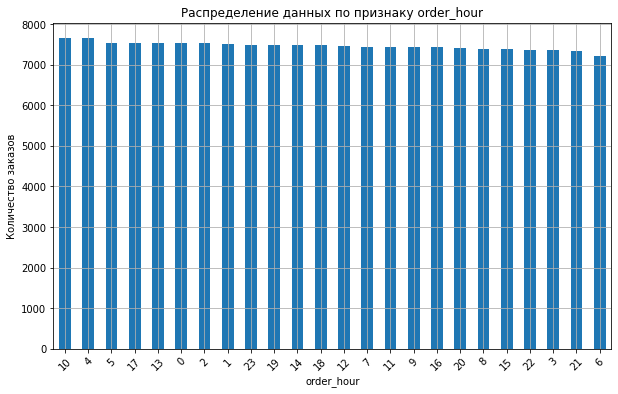


Статистические показатели:



count    179061.000
mean         11.482
std           6.922
min           0.000
25%           5.000
50%          11.000
75%          17.000
max          23.000
Name: order_hour, dtype: float64

,count,proportion
order_hour,,
10,7653,4.27
4,7650,4.27
5,7543,4.21
17,7527,4.20
13,7526,4.20
0,7523,4.20
2,7523,4.20
1,7503,4.19
23,7494,4.19


Распределение целевой переменной по категории order_hour:
order_hour
0     0.51
1     0.53
2     0.53
3     0.52
4     0.51
5     0.53
6     0.51
7     0.53
8     0.51
9     0.52
10    0.53
11    0.51
12    0.60
13    0.58
14    0.58
15    0.58
16    0.56
17    0.58
18    0.58
19    0.55
20    0.59
21    0.57
22    0.58
23    0.58
Name: late_delivery_risk, dtype: float64


In [43]:
for col in ['order_month','order_weekday','order_hour']:
    visual_numeric_2(df_order, col)

После анализа признаков `order_month`, `order_weekday` и `order_hour` можно сделать следующий вывод:
 - наибольшее количество заказов приходится на январь (9,96%), наименьшее на ноябрь (6,92%). В целом распределение по месяцам достаточно равномерное;
 - количество заказов не различается в зависимости от дня недели;
 - распределение заказов по часами также равномерное. При этом есть небольшое повышение доли задержек во второй половине дня с 13 до 24 часов.

По результатам анализа числовых признаков аномальных значений, требующих удаления, не выявлено.

Медианное значение суммарной выручки клиентов находится на уровне 1294, при этом присутствуют клиенты с выручкой более 9000. Большинство клиентов совершают от 1 до 5 заказов. Максимально возможная грубина скидки составляет 25%. Наблюдается положительная связь между суммарной выручкой и количеством заказов. При этом клиенты с высокой суммарной выручкой преимущественно характиризуются более низкой долей проблемных заказов.

Основная часть клиентов совершала последний заказ в течение последних 308 дней, медианное значение составляет 160 дней. 

Основная масса товаров сосредоточена в диапазоне относительно невысоких цен: медианная стоимость составляет 59,99, при этом 75% товаров имеют цену не выше 199,99. 

Распределение заказов по месяцам, дням недели и часам в целом достаточно равномерное. При этом в дневное и вечернее время (с 13 до 24 часов) наблюдается некоторое повышение доли задержек, что может быть полезно при построении модели.

#### Корреляционный анализ

In [44]:
interval_cols = ['item_price']
corr_df = df_order.drop(columns = ['customer_id','order_id'])

correlation_matrix = corr_df.phik_matrix(interval_cols = interval_cols)
correlation_matrix.loc[correlation_matrix.index!= 'late_delivery_risk'][['late_delivery_risk']].sort_values(by='late_delivery_risk', ascending = False)

,late_delivery_risk
shipping_mode,0.653619
order_hour,0.075047
order_month,0.007246
item_price,0.004760
order_weekday,0.001692
category_name,0.000000


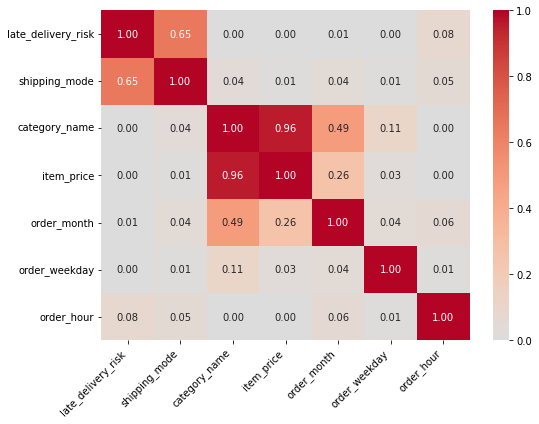

In [45]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f', 
    cmap='coolwarm',
    center=0
)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)              
plt.tight_layout()
plt.show()

Анализ корреляционной матрицы показал, что наиболее сильная связь с целевой переменной `late_delivery_risk` наблюдается у признака режим доставки `shipping_mode` (phik - 0,65). Слабая связь наблюдается с временем покупки `order_hour` (0.075). С остальными признаки связь практически отсутствует. 

В результате корреляционного анализа признаков, можно отметить сильную связь между признаками `category_name` и `item_price` (0,96), а также умеренную связь `order_month` и `category_name` (0,49). Необходимо проверить признаки на наличие мульткоолинеарности после разделения на выборки, и в случае связи выше 0,95 оставить один из признаков с наименьшей связью с целевой переменной.

__Вывод__

Целевая переменная `late_delivery_risk` представлена двумя классами: 0 — заказ доставлен вовремя, 1 — заказ доставлен с задержкой. Подтверждается умеренный дисбаланс классов: 45% заказов доставлены вовремя, 55% — с задержкой.

В ходе географического анализа обнаружены 158 точек, расположенных за пределами основного региона присутствия компании. В соответствии с условиями задания все наблюдения, долгота которых выходит за пределы диапазона от -125 до -20, исключены из датасета. Вместе с профилями клиентов удалены связанные с ними заказы для сохранения целостности данных. Явной зависимости между географическим расположением клиентов и долей проблемных заказов не выявлено.

Среди категориальных признаков наиболее информативным оказался `shipping_mode`: доля задержек существенно различается в зависимости от режима доставки. Наибольшая доля задержанных заказов наблюдается для `First Class` (0,95) и `Second Class` (0,77). Для `category_name` выраженных различий в доле задержек не выявлено. Типы данных обоих признаков приведены к category.

Анализ временных признаков показал, что распределение заказов по месяцам и дням недели достаточно равномерное. При этом наблюдается небольшое повышение доли задержек во второй половине дня (с 13 до 24 часов).

По результатам анализа числовых признаков аномальных значений, требующих удаления, не выявлено. Медианная суммарная выручка клиентов составляет 1294, большинство клиентов совершают от 1 до 5 заказов. Наблюдается положительная связь между суммарной выручкой и количеством заказов. Клиенты с высокой выручкой преимущественно характеризуются более низкой долей проблемных заказов. Медианная стоимость товара составляет 59,99.

Корреляционный анализ показал наиболее сильную связь с целевой переменной у признака `shipping_mode` (phik = 0,65). Слабая связь наблюдается у `order_hour` (0,075).С остальными признаки связь практически отсутствует. Также выявлена высокая взаимосвязь между `category_name` и `item_price` (0,96), которую необходимо дополнительно проверить после разделения данных на выборки.

Таким образом, в ходе EDA выявлены информативные признаки, наиболее значимым из которых предварительно является `shipping_mode`. Географические выбросы исключены, типы данных категориальных признаков скорректированы. Остальные признаки сохранены для дальнейшего моделирования.

<h3 id="section6">6. Предобработка данных</h3>

Разделим датафрейм на выборки с помощью `GroupShuffleSplit`, что исключить попадание одного клиента в разные выборки.

In [46]:
groups = df_order['customer_id']

gss = GroupShuffleSplit(n_splits=1,
                       test_size=0.4,
                       random_state=RANDOM_STATE)

train_idx, val_test_idx = next(gss.split(df_order, groups=groups))

df_train = df_order.iloc[train_idx]
df_val_test = df_order.iloc[val_test_idx]

gss_2 = GroupShuffleSplit(n_splits=1,
                       test_size=0.5,
                       random_state=RANDOM_STATE)

val_idx, test_idx = next(gss_2.split(df_val_test, groups=df_val_test['customer_id']))

df_val = df_val_test.iloc[val_idx]
df_test = df_val_test.iloc[test_idx]

In [47]:
train_check = set(df_train['customer_id'])
val_check = set (df_val['customer_id'])
test_check = set (df_test['customer_id'])
print ('Пересечение train и val:', len(train_check & val_check))
print ('Пересечение val и test:', len(test_check  & val_check))
print ('Пересечение test и train:', len(test_check  & train_check))

Пересечение train и val: 0
Пересечение val и test: 0
Пересечение test и train: 0


Распределение целевой переменной в выборках:

In [48]:
for name, data in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f"\n{name}")
    print(data['late_delivery_risk'].value_counts(normalize=True).round(2).to_string())


train
late_delivery_risk
1    0.55
0    0.45

val
late_delivery_risk
1    0.55
0    0.45

test
late_delivery_risk
1    0.55
0    0.45


Построим корреляцию на train:

,late_delivery_risk
shipping_mode,0.649784
order_hour,0.067511
order_month,0.013009
item_price,0.006115
order_weekday,0.005567
category_name,0.000000


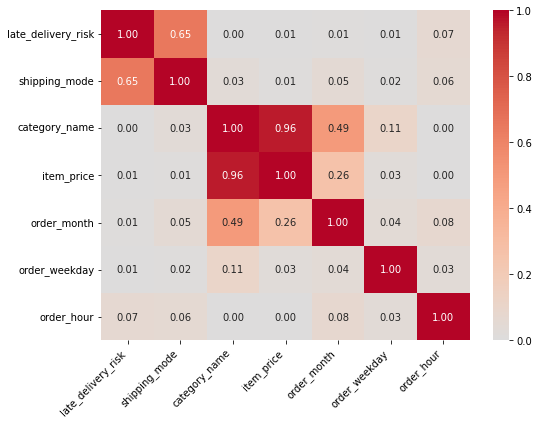

In [49]:
corr_train = df_train.drop(columns = ['customer_id','order_id'])
corr_matrix_train = corr_train.phik_matrix(interval_cols = interval_cols)

display((corr_matrix_train.loc[corr_matrix_train.index!= 'late_delivery_risk'][['late_delivery_risk']]
         .sort_values(by='late_delivery_risk', ascending = False)))

plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix_train,
    annot=True,
    fmt='.2f', 
    cmap='coolwarm',
    center=0
)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)              
plt.tight_layout()
plt.show()

Мультиколлинеарность между признаками `categore_name` и `item_price` сохраняется, поэтому исключим `category_name`
из пространства признаков при построении моделей.

Определим колоники для удаления, которые не помогут нам при построении модели, а также саму целевую переменную.

In [50]:
drop_columns = ['order_id','customer_id','late_delivery_risk','category_name', 'late_delivery_risk']
feature_columns = [col for col in df_train.columns if col not in drop_columns]

Сформируем итоговые выборки:

In [51]:
X_train, y_train = df_train[feature_columns], df_train['late_delivery_risk']
X_val, y_val = df_val[feature_columns], df_val['late_delivery_risk']
X_test, y_test = df_test[feature_columns], df_test['late_delivery_risk']

print ('Размер тренировочной выборки:',X_train.shape)
print ('Размер валидационной выборки:',X_val.shape)
print ('Размер тестовой выборки:',X_test.shape)

Размер тренировочной выборки: (107153, 5)
Размер валидационной выборки: (35584, 5)
Размер тестовой выборки: (36324, 5)


<h3 id="section7">7. Обучение базовых моделей</h3>

Обучим логистическую регрессию и `CatBoostClassifier` и оценим их качество.

In [52]:
numeric_features = ['item_price']
categorical_features_CB = [col for col in X_train.columns if col not in numeric_features]
cyclic_features = ['order_month','order_weekday','order_hour']
categorical_features_LR = [col for col in X_train.columns if col not in numeric_features + cyclic_features]

print (f'Числовые признаки {len(numeric_features)}:', numeric_features)
print (f'Категориальные признаки для CatBoost {len(categorical_features_CB)}:', categorical_features_CB)
print (f'Временные признаки {len(cyclic_features)}:', cyclic_features,)
print (f'Категориальные признаки для LogisticRegression {len(categorical_features_LR)}:', categorical_features_LR)

Числовые признаки 1: ['item_price']
Категориальные признаки для CatBoost 4: ['shipping_mode', 'order_month', 'order_weekday', 'order_hour']
Временные признаки 3: ['order_month', 'order_weekday', 'order_hour']
Категориальные признаки для LogisticRegression 1: ['shipping_mode']


Трансформер для тригонометрического кодирования признаков `order_month`, `order_weekday`, `order_hour`.

In [53]:
def cycl_transform(X):
    df_transform = pd.DataFrame(index=X.index)
    
    df_transform['order_month_sin'] = np.sin(2 * np.pi * X['order_month'] / 12)
    df_transform['order_month_cos'] = np.cos(2 * np.pi * X['order_month'] / 12)
    
    df_transform['order_weekday_sin'] = np.sin(2 * np.pi * X['order_weekday'] / 7)
    df_transform['order_weekday_cos'] = np.cos(2 * np.pi * X['order_weekday'] / 7)
    
    df_transform['order_hour_sin'] = np.sin(2 * np.pi * X['order_hour'] / 24)
    df_transform['order_hour_cos'] = np.cos(2 * np.pi * X['order_hour'] / 24)
    
    return df_transform

cycl_transformer = FunctionTransformer(cycl_transform).set_output(transform='pandas')

Напишем пайплайн обработки признаков для логистической регрессии, CatBoost передадим категориальные признаки через cat_features.

In [54]:
preprocessor_LR = ColumnTransformer(transformers = [
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(sparse_output = False, handle_unknown = 'ignore'),categorical_features_LR),
    ('cycl',cycl_transformer,cyclic_features)
], remainder='drop')

In [55]:
LR_pipeline = Pipeline([
    ('preprocessor',preprocessor_LR),
    ('classifier', LogisticRegression(max_iter=1000,random_state=RANDOM_STATE))
])

In [56]:
CB_model = CatBoostClassifier(random_state=RANDOM_STATE,
                              eval_metric="AUC",
                              verbose=0)

Обучим модели и посчитаем ROC-AUC на тестовой и валидационной выборке:

In [57]:
LR_pipeline.fit(X_train, y_train)

CB_model.fit(X_train,
             y_train,
             eval_set = [(X_val, y_val)],
             early_stopping_rounds=50,
             cat_features = categorical_features_CB)

In [58]:
y_pred_train_LR = LR_pipeline.predict_proba(X_train)[:,1]
y_pred_train_CB = CB_model.predict_proba(X_train)[:,1]

train_metric_LR = roc_auc_score(y_train, y_pred_train_LR)
train_metric_CB = roc_auc_score(y_train, y_pred_train_CB)

print(f'ROC-AUC Logistic Regression на тренировочной выборке: {train_metric_LR:.3f}')
print(f'ROC-AUC CatBoost на тренировочной выборке: {train_metric_CB:.3f}')

y_pred_val_LR = LR_pipeline.predict_proba(X_val)[:,1]
y_pred_val_CB = CB_model.predict_proba(X_val)[:,1]

val_metric_LR = roc_auc_score(y_val, y_pred_val_LR)
val_metric_CB = roc_auc_score(y_val, y_pred_val_CB)

print(f'ROC-AUC Logistic Regression на валидационной выборке: {val_metric_LR:.3f}')
print(f'ROC-AUC CatBoost на валидационной выборке: {val_metric_CB:.3f}')

ROC-AUC Logistic Regression на тренировочной выборке: 0.727
ROC-AUC CatBoost на тренировочной выборке: 0.857
ROC-AUC Logistic Regression на валидационной выборке: 0.737
ROC-AUC CatBoost на валидационной выборке: 0.803


По результатам обучения базовых моделей `CatBoost` показал более высокое качество по сравнению с `Logistic Regression`. На валидационной выборке ROC-AUC составил `0,803` против `0,737` у логистической регрессии. Полученные значения будут использоваться в качестве базового уровня для оценки эффективности моделей после добавления новых признаков.

<h3 id="section8">8. Кластеризация по признакам, связанным с местоположением</h3>

На этом этапе превратим исходные координаты `customer_lat` и `customer_lon` в полезный для модели признак - логистическую зону.

Для предотвращения утечки, разделим `df_customer` на три выборки согласно уже сформированным выборкам из `df_order`.

In [59]:
customer_train = df_customer[df_customer['customer_id'].isin(df_train['customer_id'])].copy()
customer_val = df_customer[df_customer['customer_id'].isin(df_val['customer_id'])].copy()
customer_test = df_customer[df_customer['customer_id'].isin(df_test['customer_id'])].copy()

print ('Размер тренировочной выборки customer:',customer_train.shape)
print ('Размер валидационной выборки customer:',customer_val.shape)
print ('Размер тестовой выборки customer:',customer_test.shape)

Размер тренировочной выборки customer: (12296, 8)
Размер валидационной выборки customer: (4099, 8)
Размер тестовой выборки customer: (4099, 8)


Поскольку широта и долгота имеют разный масштаб и изменения значений, то их необходимо масштабировать с помощью `StandardScaler()`. 

Используем метод локтя для поиска обоснованной границы количества кластеров.

In [60]:
ks = range(2,12)
wcss = []

for k in ks:
    kmeans_pipe = Pipeline([
        ('prep', StandardScaler()),
        ('kmeans', KMeans(n_clusters = k, init='k-means++', random_state=RANDOM_STATE))
    ])
    
    kmeans_pipe.fit(customer_train[['customer_lat','customer_lon']])
    inertia = kmeans_pipe.named_steps['kmeans'].inertia_
    wcss.append(inertia)

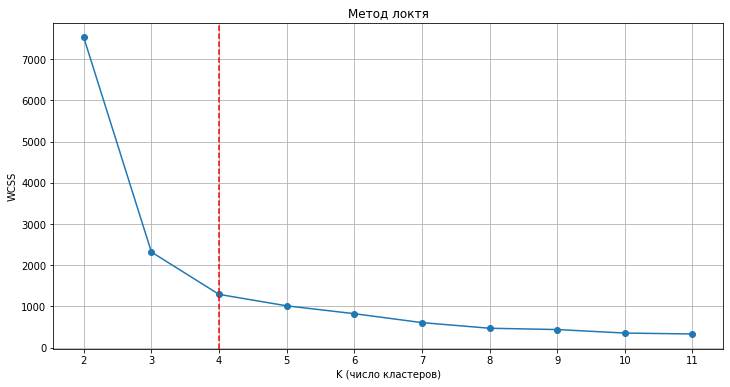

In [61]:
elbow = 4

plt.figure(figsize=(12,6))
plt.plot(list(ks), wcss, marker='o')
plt.xticks(list(ks))
plt.xlabel('K (число кластеров)')
plt.ylabel('WCSS')
plt.title('Метод локтя')
plt.grid(True)
plt.axvline(elbow, linestyle='--', color='red')
plt.show()

В результате перебора цикла с кластерами от 2 до 12, видно, что наибольшее уменьшение внутрикластерного расстояния достигается при 4 кластерах, при большем числе кластеров улучшение становятся незначительными. Премем `n_clusters = 4` и обучим KMeans.

In [62]:
kmeans_pipe_geo = Pipeline([
        ('prep', StandardScaler()),
        ('kmeans', KMeans(n_clusters = 4, init='k-means++', random_state=RANDOM_STATE))
    ])
    
kmeans_pipe_geo.fit(customer_train[['customer_lat','customer_lon']])

Pipeline(steps=[('prep', StandardScaler()),
                ('kmeans', KMeans(n_clusters=4, random_state=42))])

Получим метки классов, координаты центроидов и построим график.

In [63]:
train_geo_cluster = kmeans_pipe_geo.predict(customer_train[['customer_lat','customer_lon']])
val_geo_cluster = kmeans_pipe_geo.predict(customer_val[['customer_lat','customer_lon']])
test_geo_cluster = kmeans_pipe_geo.predict(customer_test[['customer_lat','customer_lon']])

In [64]:
train_geo_centers = kmeans_pipe_geo.named_steps['kmeans'].cluster_centers_
train_geo_centers = kmeans_pipe_geo.named_steps['prep'].inverse_transform(train_geo_centers)

In [65]:
customer_train['geo_cluster'] = train_geo_cluster
customer_val['geo_cluster'] = val_geo_cluster
customer_test['geo_cluster'] = test_geo_cluster

data_geo_clusters = pd.concat([customer_train, customer_val, customer_test])

In [66]:
geo_stat = data_geo_clusters.groupby('geo_cluster').agg(customers = ('customer_id', 'nunique'))
geo_stat['share'] = (geo_stat['customers']/len(data_geo_clusters)).round(2)

display(geo_stat)

,customers,share
geo_cluster,,
0,2275,0.11
1,7867,0.38
2,5572,0.27
3,4780,0.23


Рассчитаем силуэтный коэффициент:

In [67]:
X_geo_scaled = kmeans_pipe_geo.named_steps['prep'].transform(customer_train[['customer_lat','customer_lon']])

silhouette_avg = silhouette_score(X_geo_scaled, train_geo_cluster)
print (f'Силуэтный коэффициент: {silhouette_avg:.3f}')

Силуэтный коэффициент: 0.759


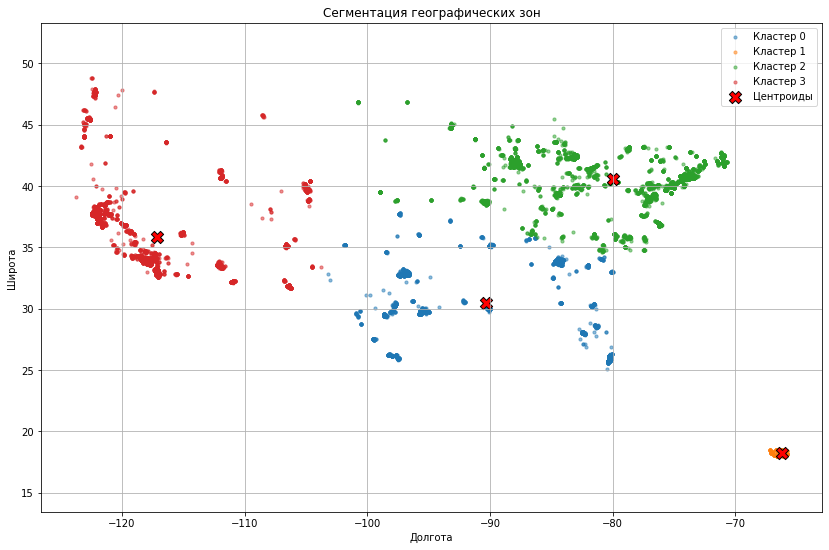

In [68]:
plt.figure(figsize=(14,9))
colors = plt.cm.tab10.colors

for cluster in range(4):
    data = data_geo_clusters[data_geo_clusters['geo_cluster']==cluster]
    
    plt.scatter(data['customer_lon'],
                data['customer_lat'],
               color = colors[cluster],
               alpha=0.5,
               s=10,
               label=f'Кластер {cluster}')

plt.scatter (train_geo_centers[:,1],
            train_geo_centers[:,0],
            marker='X',
            s=150,
            color='red',
            edgecolor='black',
            linewidth=1,
            label = 'Центроиды')

plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.title('Сегментация географических зон')

plt.legend()
plt.axis('equal')
plt.grid()
plt.show()

В результате кластеризации координат `customer_lat` и `customer_lon` сформирован новый признак - логистическая зона клиента (`geo_cluster`).

Таблица `df_customer` разделена на выборки в соответствии с разделением таблицы `df_order`. С помощью метода локтя определено оптимальное количество кластеров - 4 . Модель `KMeans` обучена на тренировочной выборке, после чего применена к валидационной и тестовой выборкам.

Полученные кластеры и их центроиды представлены на графике. Наиболее многочисленным оказался кластер 1 - 7867 (38%) клиентов,  далее следуют кластер 2 — 5572 клиента(27%), кластер 3 — 4780 (23%). Наименьший кластер 0 объединяет 2275 клиентов (11%). 

На карте прослеживается выраженное географическое распределение групп: выделяются западная, северо-восточная, южная часть материка и отельно зона в районе Пуэрто-Рико.  

Визуализация показала, что сформированные кластеры имеют достаточно компактное расположение, что позволяет использовать признак для дальнешего обучения моделей.

Дополнительно качество кластеризации оценено с помощью силуэтного коэффициента, значение которого составило 0.759. Это свидетельствует о хорошем разделении сформированных групп.

<h3 id="section9">9. Кластеризация по признакам профилей клиентов</h3>

Сформируем новый признак профиля клиента на основании столбцов `recency`, `total_orders`, `total_sales`, `return_rate` и `avg_discount`.

Определим список столбцов, на котором будем обучать `KMeans`:

In [69]:
cluster_features = ['recency','total_orders','total_sales','return_rate','avg_discount']

In [70]:
wcss_beh = []

for k in ks:
    kmeans_beh_pipe = Pipeline([
        ('prep', StandardScaler()),
        ('kmeans', KMeans(n_clusters = k, init='k-means++', random_state=RANDOM_STATE))
    ])
    
    kmeans_beh_pipe.fit(customer_train[cluster_features])
    inertia = kmeans_beh_pipe.named_steps['kmeans'].inertia_
    wcss_beh.append(inertia)

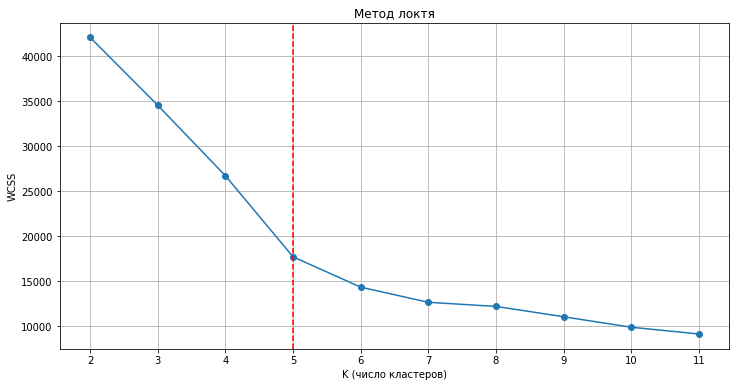

In [71]:
elbow_beh = 5

plt.figure(figsize=(12,6))
plt.plot(list(ks), wcss_beh, marker='o')
plt.xticks(list(ks))
plt.xlabel('K (число кластеров)')
plt.ylabel('WCSS')
plt.title('Метод локтя')
plt.grid(True)
plt.axvline(elbow_beh, linestyle='--', color='red')
plt.show()

In [72]:
kmeans_pipe_beh = Pipeline([
        ('prep', StandardScaler()),
        ('kmeans', KMeans(n_clusters = 5, init='k-means++', random_state=RANDOM_STATE))
    ])
    
kmeans_pipe_beh.fit(customer_train[cluster_features])

Pipeline(steps=[('prep', StandardScaler()),
                ('kmeans', KMeans(n_clusters=5, random_state=42))])

In [73]:
X_beh_scaled = kmeans_pipe_beh.named_steps['prep'].transform(customer_train[cluster_features])
labels = kmeans_pipe_beh.named_steps['kmeans'].labels_
silhouette_avg_beh = silhouette_score(X_beh_scaled, labels)
print (f'Силуэтный коэффициент: {silhouette_avg_beh:.3f}')

Силуэтный коэффициент: 0.416


Силуэтный коэффициент 0,416 свидетельствует об умеренной степени разделения групп: клиенты внутри кластеров обладают определённым сходством, однако между отдельными сегментами сохраняются пересечения. 

In [74]:
train_beh_cluster = kmeans_pipe_beh.predict(customer_train[cluster_features])
val_beh_cluster = kmeans_pipe_beh.predict(customer_val[cluster_features])
test_beh_cluster = kmeans_pipe_beh.predict(customer_test[cluster_features])

In [75]:
customer_train['beh_cluster'] = train_beh_cluster
customer_val['beh_cluster'] = val_beh_cluster
customer_test['beh_cluster'] = test_beh_cluster

data_beh_cluster = pd.concat([customer_train, customer_val, customer_test])

Статистическая характеристика кластеров:

In [76]:
clister_beh_stats = customer_train.groupby('beh_cluster').agg(
    customers=('customer_id', 'count'),
    total_sales_mean=('total_sales', 'mean'),
    total_orders_mean=('total_orders', 'mean'),
    avg_discount_mean=('avg_discount', 'mean'),
    return_rate_mean=('return_rate', 'mean'),
    recency_mean=('recency', 'mean')
)

clister_beh_stats['share'] = (clister_beh_stats['customers']/len(customer_train))

display(clister_beh_stats.round(3))

,customers,total_sales_mean,total_orders_mean,avg_discount_mean,return_rate_mean,recency_mean,share
beh_cluster,,,,,,,
0,2479,1534.453,3.026,0.102,0.027,518.369,0.202
1,3002,399.570,1.195,0.051,0.001,78.945,0.244
2,4140,3308.471,5.980,0.101,0.045,236.044,0.337
3,2393,327.654,1.144,0.167,0.001,76.997,0.195
4,282,522.442,1.355,0.108,0.926,171.603,0.023


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_train[cluster_features])

tsne = TSNE(n_components=2,
           perplexity=50,
           learning_rate=200,
           random_state=RANDOM_STATE,
           init='pca',
           max_iter=1000)

X_tsne = tsne.fit_transform(X_scaled)

In [ ]:
tsne_df = pd.DataFrame(X_tsne, columns=['tsne_1', 'tsne_2'])

color_values = customer_train['beh_cluster'].values
tsne_df['beh_cluster'] = color_values

In [ ]:
plt.figure(figsize=(12,8))

scatter = plt.scatter(tsne_df['tsne_1'],
                      tsne_df['tsne_2'],
                      c=tsne_df['beh_cluster'],
                      s=12,
                      alpha=0.7)

plt.title('t-SNE: визуализация объектов по поведенческим признакам')
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')
plt.colorbar(scatter, label = 'beh_cluster')

plt.tight_layout()
plt.show()


По графику видно, что `t-SNE` в целом выделяет те группы, соответствующие результатам KMeans. Большинство кластеров имеют выраженное разделение. Некоторые группы частично пересекаются, что отражает сходство отдельных клиентво по покупательским характеристикам.

В результате кластеризации признаков `recency`, `total_orders`, `total_sales`, `return_rate` и `avg_discount` создан новый признак, отражающий профиль клиента. 

С помощью метода локтя определено оптимальное количество кластеров - 5. Визулазиция методом t-SNE в целом подтвердила результаты KMeans: большинство кластеров действительно имеют выраженное разделение.

При анализе статистических характеристик выделено несколько яркий групп:
- кластер 2 "Постоянные лояльные": клиенты с наибольшии количеством заказов и суммарной выручкой;
- кластер 3 "Экономные": клиенты с самым высоким уровнем скидки и низкой выручкой;
- кластер 4 "С высокой долей возвратов": небольшая группа с аномально высоким уровнем возратов (93%).

<h3 id="section10">10. Обучение моделей на новых признаках</h3>

Добавим результаты кластеризации в данные для обучения моделей.

In [ ]:
df_train_cluster =  df_train.merge(data_beh_cluster[['customer_id',
                                                     'geo_cluster',
                                                     'beh_cluster']],
                                   on = 'customer_id',
                                   how = 'inner')

df_val_cluster =  df_val.merge(data_beh_cluster[['customer_id',
                                                     'geo_cluster',
                                                     'beh_cluster']],
                                   on = 'customer_id',
                                   how = 'inner')

df_test_cluster =  df_test.merge(data_beh_cluster[['customer_id',
                                                     'geo_cluster',
                                                     'beh_cluster']],
                                   on = 'customer_id',
                                   how = 'inner')

Проверим пропуски и отсутствие дублей столбцов:

In [ ]:
for df in df_train_cluster, df_val_cluster, df_test_cluster:
    display(df.head())
    print (df[['geo_cluster','beh_cluster']].isna().sum(),'\n')

Сформируем новые выборки и списки категориальных признаков:

In [ ]:
feature_columns_cluster = feature_columns + ['geo_cluster', 'beh_cluster']

X_train_cluster = df_train_cluster[feature_columns_cluster] 
X_val_cluster = df_val_cluster[feature_columns_cluster] 
X_test_cluster = df_test_cluster[feature_columns_cluster]
print ('Размер тренировочной выборки:',X_train_cluster.shape)
print ('Размер валидационной выборки:',X_val_cluster.shape)
print ('Размер тестовой выборки:',X_test_cluster.shape)

In [ ]:
categorical_features_CB_cluster = [col for col in X_train_cluster.columns if col not in numeric_features]
categorical_features_LR_cluster = [col for col in X_train_cluster.columns if col not in numeric_features + cyclic_features]

print (f'Числовые признаки {len(numeric_features)}:', numeric_features)
print (f'Категориальные признаки для CatBoost {len(categorical_features_CB_cluster)}:',
       categorical_features_CB_cluster)
print (f'Временные признаки {len(cyclic_features)}:', cyclic_features,)
print (f'Категориальные признаки для LogisticRegression {len(categorical_features_LR_cluster)}:',
       categorical_features_LR_cluster)

Перепишем пайплайн для логистической регрессии:

In [ ]:
preprocessor_LR_cluster = ColumnTransformer(transformers = [
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(sparse_output = False, handle_unknown = 'ignore'),categorical_features_LR_cluster),
    ('cycl',cycl_transformer,cyclic_features)
], remainder='drop')

In [ ]:
LR_pipeline_cluster = Pipeline([
    ('preprocessor',preprocessor_LR_cluster),
    ('classifier', LogisticRegression(max_iter=1000,random_state=RANDOM_STATE))
])

CB_model_cluster = CatBoostClassifier(random_state=RANDOM_STATE,
                                      eval_metric="AUC",
                                      verbose=0)

In [ ]:
LR_pipeline_cluster.fit(X_train_cluster, y_train)

CB_model_cluster.fit(X_train_cluster,
             y_train,
             eval_set = [(X_val_cluster, y_val)],
             early_stopping_rounds=50,
             cat_features = categorical_features_CB_cluster)

In [ ]:
y_pred_train_LR_cluster = LR_pipeline_cluster.predict_proba(X_train_cluster)[:,1]
y_pred_train_CB_cluster = CB_model_cluster.predict_proba(X_train_cluster)[:,1]

train_metric_LR_cluster = roc_auc_score(y_train, y_pred_train_LR_cluster)
train_metric_CB_cluster = roc_auc_score(y_train, y_pred_train_CB_cluster)

y_pred_val_LR_cluster = LR_pipeline_cluster.predict_proba(X_val_cluster)[:,1]
y_pred_val_CB_cluster = CB_model_cluster.predict_proba(X_val_cluster)[:,1]

val_metric_LR_cluster = roc_auc_score(y_val, y_pred_val_LR_cluster)
val_metric_CB_cluster = roc_auc_score(y_val, y_pred_val_CB_cluster)

print(f'ROC-AUC Logistic Regression на тренировочной выборке с новыми признаками : {train_metric_LR_cluster:.3f}')
print(f'ROC-AUC CatBoost на тренировочной выборке с новыми признаками: {train_metric_CB_cluster:.3f}')
print(f'ROC-AUC Logistic Regression на валидационной выборке с новыми признаками: {val_metric_LR_cluster:.3f}')
print(f'ROC-AUC CatBoost на валидационной выборке с новыми признаками: {val_metric_CB_cluster:.3f}')

Выведем метрики для сравнения:

In [ ]:
results = pd.DataFrame({
    'Модель': [
        'Logistic Regression',
        'Logistic Regression (cluster)',
        'CatBoost',
        'CatBoost (cluster)'],
    'ROC-AUC Train': [
        train_metric_LR,
        train_metric_LR_cluster,
        train_metric_CB,
        train_metric_CB_cluster],
    'ROC-AUC Validation': [
        val_metric_LR,
        val_metric_LR_cluster,
        val_metric_CB,
        val_metric_CB_cluster]
})

display(results.round(3))

Добавление географических и поведенческих кластеризационных метрика ROC-AUC у логистиской регрессии выросла с 0,737 до 0,742, а для CatBoost обеспечило незначительное улучшение — с 0,803 до 0,804. При этом наблюдается некоторое увеличение разрыва между обучающей и валидационной метриками.

Таким образом, CatBoost c признаками после кластеризации выбран в качестве наиболее перспективной модели для дальнейшей оптимизации. На следующем этапе оценим качество лучшей модели на тестовой выборке.

<h3 id="section11">11. Тестирование лучшей модели</h3>

Расчитаем предсказание на тестовой выборке для лучшей модели:

In [ ]:
y_proba_test = CB_model_cluster.predict_proba(X_test_cluster)[:,1]
y_pred_test = (y_proba_test>=0.7).astype(int)

roc_auc_test = roc_auc_score(y_test, y_proba_test)
precision = precision_score (y_test, y_pred_test)
recall = recall_score(y_test, y_pred_test)

print (f'ROC-AUC на тестовой выборке: {roc_auc_test:.3f}')
print (f'Precision на тестовой выборке: {precision:.3f}')
print (f'Recall на тестовой выборке: {recall:.3f}')

Построим матрицу ошибок при заданном бизнес-пороге 0.7: 

In [ ]:
matrix = confusion_matrix(y_test,y_pred_test)

fig,ax = plt.subplots(figsize =(10,8))
ConfusionMatrixDisplay(matrix, display_labels = ['Заказ доставлен вовремя(0)', 
                                                 'Заказ доставлен с задержкой(1)']).plot(ax=ax)
plt.title('Матрица ошибок на тестовой выборке')
plt.show()

При выбранном пороге 0,7 модель значительно чаще пропускает реальные задержки (`FN = 9040`), чем выдает ложное предупреждение (`FP = 1563`). Это указывает на недостаточную полноту выявления заказов с задержкой, модель обнаруживает только 54% такиех заказов. При этом precision составляет 87%, то есть среди заказов, для которых модель прогнозирует задержку, большинство действительно задерживают.

Визуализируем важность признаков лучшей модели:

In [ ]:
importances = CB_model_cluster.feature_importances_

feature_importances = pd.DataFrame({
    'Feature' : X_test_cluster.columns ,
    'Importance' : importances
}).sort_values('Importance', ascending = False).round(4)
feature_importances

In [ ]:
X_plot = X_test_cluster
explainer = shap.TreeExplainer(CB_model_cluster)
shap_values = explainer.shap_values(X_plot)
    
plt.figure(figsize=(16,14))
shap.summary_plot(shap_values, X_plot, feature_names = X_plot.columns,max_display=15,
                  show = False)
plt.title(f'SHAP Summary Plot')
plt.tight_layout()
plt.show()

По результатам предсказания лучшей модели `CatBoost` на тестовой выборке ROC-AUC составил 0,803. Модель достигла заданного целевого показателя 0,75.

При выбранном пороге модель чаще пропускает реальные задержки, чем выдает ложное предупреждение. Это указывает на недостаточную полноту выявления заказов с задержкой, модель обнаруживает только 54% такиех заказов. При этом precision составляет 87%.

По результатам анализа важности признаков наибольший вклад в предсказание модели вносит режим доставки (`shipping_mode`) и час оформления заказа (`order_hour`). В меньшей степени модель опирается на день недели и месяц оформления заказа.

Новые признаки географической (`geo_cluster`) и поведенческой (`beh_cluster`) сегментации имеют сравнительно небольшой вклад в предсказания модели.

<h3 id="section12">12. Сохранение модели</h3>

In [ ]:
joblib.dump({'pipeline_geo_cluster' : kmeans_pipe_geo,
             'pipeline_beh_cluster': kmeans_pipe_beh,
             'numeric_features' : numeric_features,
             'categorical_features' : categorical_features_CB_cluster,
             'threshold': 0.7,
             'model' : CB_model_cluster
            },'model_artifacts')
print('Файлы успешно загружены')

Проверим корректность загрузки:

In [ ]:
model_artifacts = joblib.load('model_artifacts')
loaded_model = model_artifacts['model']

y_loaded_proba = loaded_model.predict_proba(X_test_cluster)[:,1]
y_loaded_pred = (y_loaded_proba >= 0.7).astype(int)

print ('Вероятности совпадают:', np.allclose(y_loaded_proba, y_proba_test))
print ('Предсказания совпадают:', np.allclose(y_loaded_pred,y_pred_test))

<h3 id="section13">13. Выводы по проекту</h3>

В ходе проекта была разработана модель прогнозирования риска задержки доставки заказов компании CargaPronto. В данных был выявлен умеренный дисбаланс классов: 55% заказов доставляются с задержкой и 45% вовремя. Географические выбросы исключены, а данные разделены на три выборки с учетом группировки по клиентам, что позволило избежать попадания заказов одного клиента в разные выборки.

В качестве базовых моделей обучены Logistic Regression и CatBoost. Лучший результат показал алгоритм CatBoost (0,804 против 0,742 на валидации). После добавления кластеризационных признаков качество модели незначительно улучшилось. Итоговый ROC-AUC на тестовой выборке составил 0,803, что выше целевого значения 0,75. По сравнению с  логистической регрессией CatBoost продемонстрировал более высокую предсказательную способность. Наиболее значимыми признаками для прогноза итоговой модели оказались режим доставки и час оформления заказа.

Кластеризация позволила выделить 4 географических зоны (geo_cluster) и 5 поведенческих сегментов клиентов (beh_cluster). 
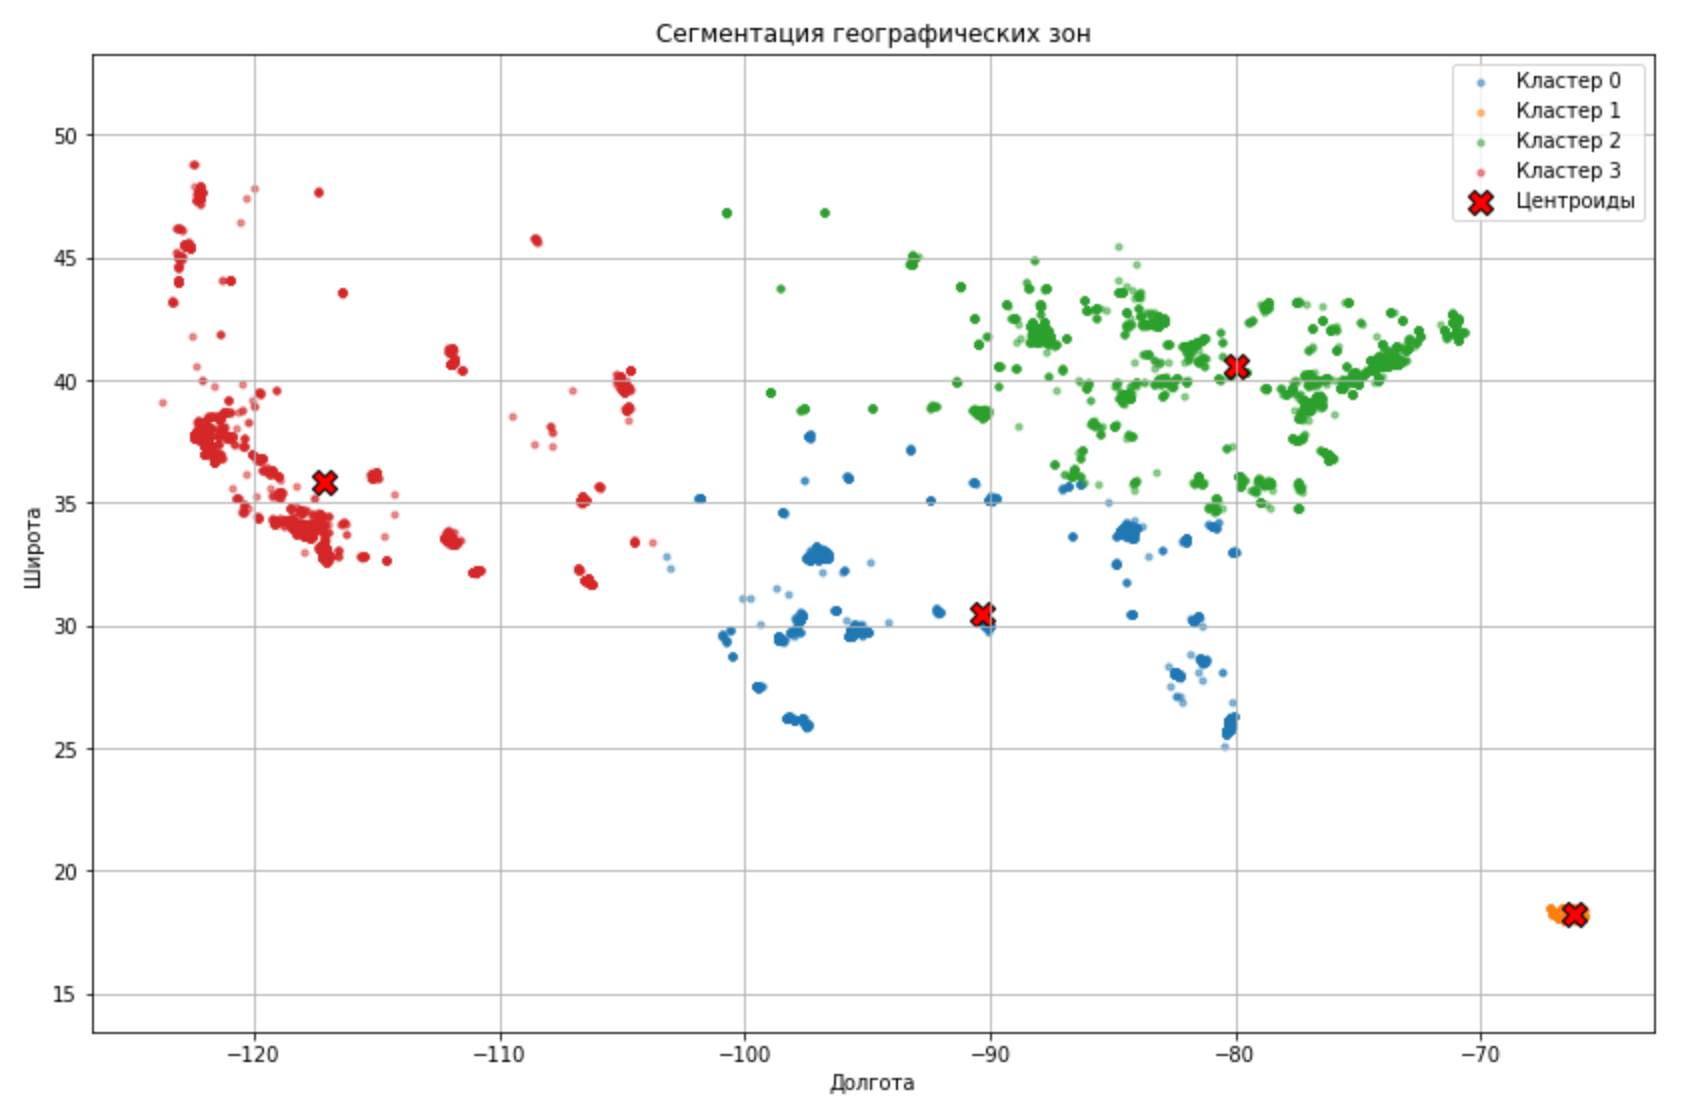
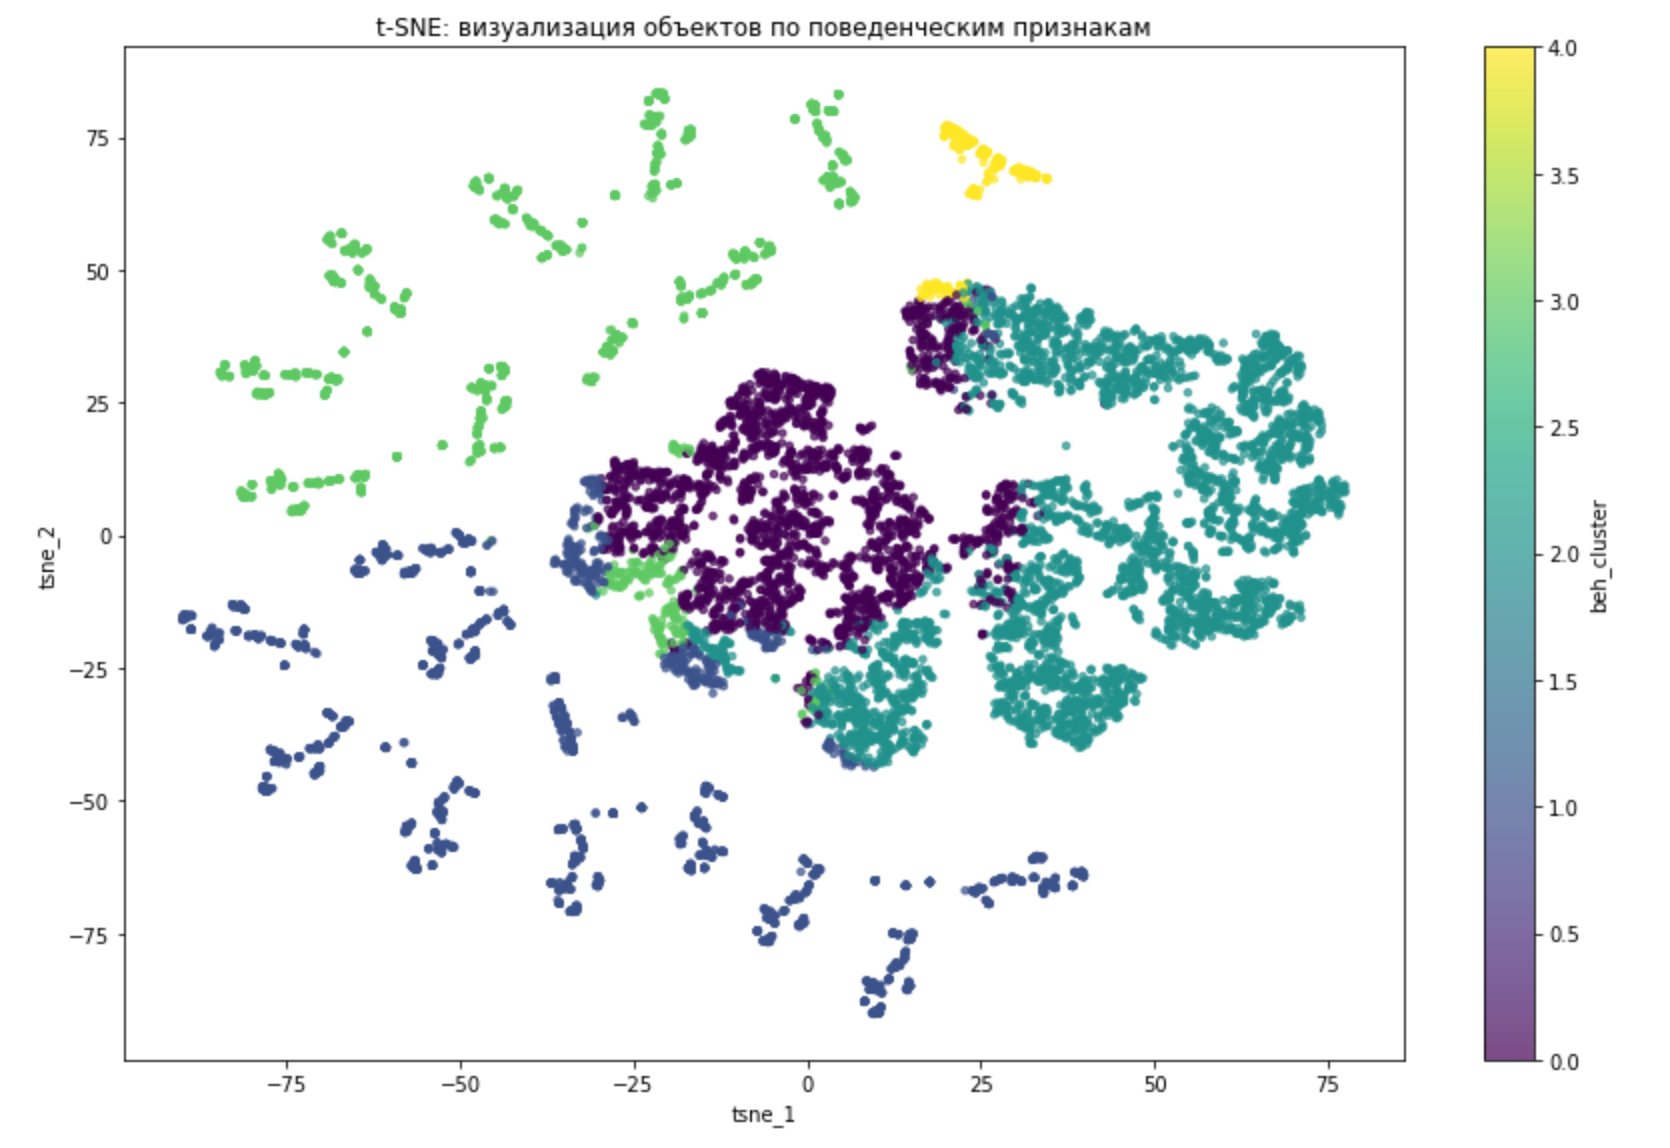

Гипотеза о влиянии клиентского профиля и географического положения на риск задержки доставки подтвердилась частично. Признаки  beh_cluster и geo_cluster имеют небольшую значимость для модели, однако их добавление позволило увеличить ROC-AUC на валидации у логистической регресии с 0,737 до 0,742 и у CatBoost с 0,803 до 0,804. Следовательно, кластеризационные признаки вносят дополнительную информацию, но не оказывают существенного влияюние на качество прогнозирования.

При установленом бизнес-пороге 0,7 модель показала Precision = 0,87 и Recall = 0,54. Это означает, что прогноз задержек достаточно точен, однако модели выявляет только около 54% фактических задержек. 

CargaPronto может использовать модель для предварительной оценки риска задержки заказов и приоритизации контроля доставки. Заказы с высоким прогнозируемым риском можно направлять на дополнительный мониторинг, а также заранее информировать клиентов о возможных задержках.